# Delivery Delay Analysis (Python)

Module 2 – pandas + matplotlib. All paths are relative to the **repository root** (the `python-work/` folder).

Sections: **P1** load, clean & merge · **P2** derived field & service-type analysis · **P3** chart & exports.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use("Agg")  
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "python":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)
print("Repository root:", ROOT.name)

Repository root: python-work


## P1 — Load, Clean & Merge

### P1.1 Load both raw CSVs and confirm numeric types

In [3]:
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
routes = pd.read_csv(RAW_DIR / "routes.csv")

deliveries["record_id"] = deliveries["record_id"].astype("int64")
deliveries[["promised_days", "actual_days"]] = deliveries[["promised_days", "actual_days"]].apply(pd.to_numeric)
for col in ["month", "route_id", "hub"]:
    deliveries[col] = deliveries[col].astype(str)
for col in ["route_id", "route", "service_type"]:
    routes[col] = routes[col].astype(str)

assert pd.api.types.is_numeric_dtype(deliveries["promised_days"])
assert pd.api.types.is_numeric_dtype(deliveries["actual_days"])

print("deliveries rows (raw):", len(deliveries))
print("routes rows:", len(routes))
print()
print(deliveries.dtypes)

deliveries rows (raw): 13
routes rows: 4

record_id        int64
month              str
route_id           str
hub                str
promised_days    int64
actual_days      int64
dtype: object


### P1.2 Remove the exact duplicate, merge with routes (left join) and validate

In [4]:
before = len(deliveries)
deliveries_clean = deliveries.drop_duplicates().reset_index(drop=True)
after = len(deliveries_clean)
print(f"Rows before de-duplication: {before}")
print(f"Rows after  de-duplication: {after}  (removed {before - after})")

df = deliveries_clean.merge(routes, on="route_id", how="left", validate="many_to_one")

assert len(df) == 12, f"Expected 12 rows, got {len(df)}"
assert df["service_type"].isna().sum() == 0, "Unmatched route_id found (NaN in service_type)"
print("\nChecks passed: 12 rows, 0 NaN in service_type")
df

Rows before de-duplication: 13
Rows after  de-duplication: 12  (removed 1)

Checks passed: 12 rows, 0 NaN in service_type


,record_id,month,route_id,hub,promised_days,actual_days,route,service_type
0,1,Jan,R1,Mumbai,2,2,Metro Link,Express
1,2,Jan,R2,Chennai,3,4,City Dash,Express
2,3,Jan,R3,Delhi,5,8,Highway Freight,Standard
3,4,Jan,R4,Mumbai,6,10,Rural Feeder,Standard
4,5,Feb,R1,Chennai,2,5,Metro Link,Express
5,6,Feb,R2,Delhi,3,3,City Dash,Express
6,7,Feb,R3,Delhi,5,10,Highway Freight,Standard
7,8,Feb,R4,Chennai,6,7,Rural Feeder,Standard
8,9,Mar,R1,Delhi,2,8,Metro Link,Express
9,10,Mar,R2,Mumbai,3,5,City Dash,Express


## P2 — Derived Field & Service-Type Analysis

In [5]:
df["delay_days"] = (df["actual_days"] - df["promised_days"]).clip(lower=0)
df["is_delayed"] = df["actual_days"] > df["promised_days"]
df[["record_id", "month", "route_id", "route", "hub", "service_type",
    "promised_days", "actual_days", "delay_days", "is_delayed"]]

,record_id,month,route_id,route,hub,service_type,promised_days,actual_days,delay_days,is_delayed
0,1,Jan,R1,Metro Link,Mumbai,Express,2,2,0,False
1,2,Jan,R2,City Dash,Chennai,Express,3,4,1,True
2,3,Jan,R3,Highway Freight,Delhi,Standard,5,8,3,True
3,4,Jan,R4,Rural Feeder,Mumbai,Standard,6,10,4,True
4,5,Feb,R1,Metro Link,Chennai,Express,2,5,3,True
5,6,Feb,R2,City Dash,Delhi,Express,3,3,0,False
6,7,Feb,R3,Highway Freight,Delhi,Standard,5,10,5,True
7,8,Feb,R4,Rural Feeder,Chennai,Standard,6,7,1,True
8,9,Mar,R1,Metro Link,Delhi,Express,2,8,6,True
9,10,Mar,R2,City Dash,Mumbai,Express,3,5,2,True


### P2.1 Service-type summary (rates computed from underlying counts, not averaged percentages)

In [6]:
summary = (
    df.groupby("service_type")
      .agg(total_records=("record_id", "count"),
           delayed_records=("is_delayed", "sum"),
           total_delay_days=("delay_days", "sum"))
      .reset_index()
)
summary["delay_incidence_rate_pct"] = (summary["delayed_records"] / summary["total_records"] * 100).round(2)
summary["total_delay_days"] = summary["total_delay_days"].astype(int)
summary["delayed_records"] = summary["delayed_records"].astype(int)

overall_rate = round(df["is_delayed"].sum() / len(df) * 100, 2)
print(f"Overall delay incidence rate: {overall_rate:.2f}%")
summary

Overall delay incidence rate: 75.00%


,service_type,total_records,delayed_records,total_delay_days,delay_incidence_rate_pct
0,Express,6,4,12,66.67
1,Standard,6,5,22,83.33


### P2.2 Route with the greatest summed delay_days and its share of the total

In [7]:
route_delay = (
    df.groupby(["route_id", "route"])["delay_days"].sum().reset_index()
      .sort_values("delay_days", ascending=False)
)
total_delay = int(df["delay_days"].sum())
max_delay = route_delay["delay_days"].max()
top_routes = route_delay[route_delay["delay_days"] == max_delay]   # keeps ALL ties

for _, r in top_routes.iterrows():
    share = r["delay_days"] / total_delay * 100
    print(f"Route with greatest summed delay_days: {r['route_id']} ({r['route']})")
    print(f"  Summed delay_days : {int(r['delay_days'])}")
    print(f"  Overall total     : {total_delay}")
    print(f"  Share of total    : {share:.2f}%")

route_delay

Route with greatest summed delay_days: R4 (Rural Feeder)
  Summed delay_days : 14
  Overall total     : 34
  Share of total    : 41.18%


,route_id,route,delay_days
3,R4,Rural Feeder,14
0,R1,Metro Link,9
2,R3,Highway Freight,8
1,R2,City Dash,3


## P3 — Chart & Exports

### P3.1 Monthly total delay_days (Jan → Feb → Mar)

month
Jan     8
Feb     9
Mar    17


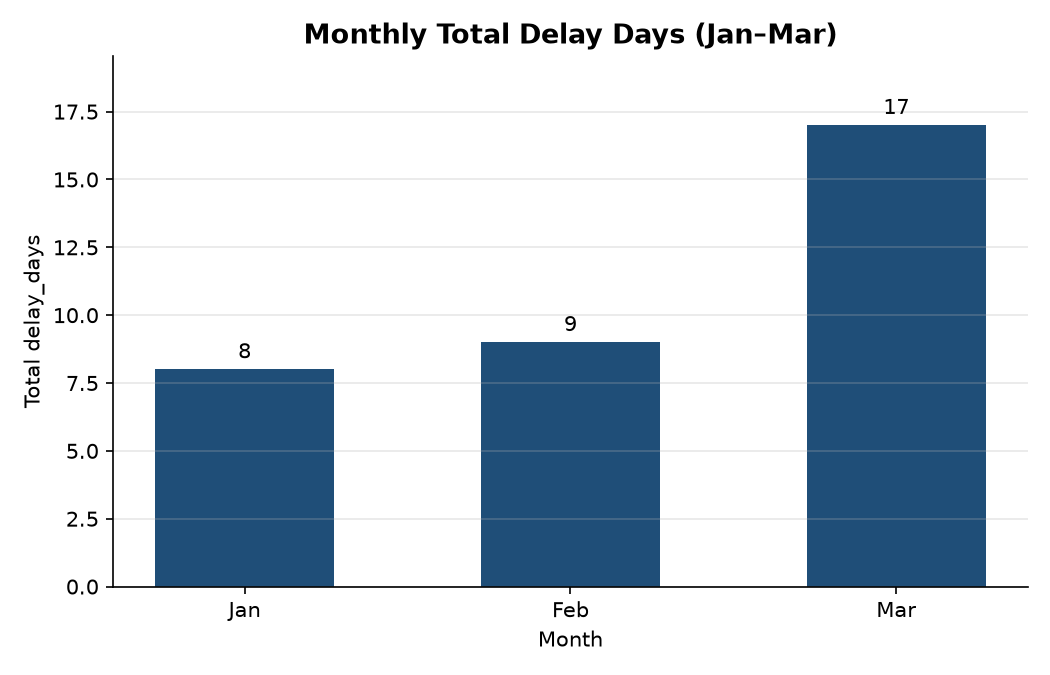

In [8]:
month_order = ["Jan", "Feb", "Mar"]
monthly = (
    df.groupby("month")["delay_days"].sum()
      .reindex(month_order)          # preserve Jan -> Feb -> Mar order
)
print(monthly.to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(monthly.index, monthly.values, color="#1F4E78", width=0.55)
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_title("Monthly Total Delay Days (Jan–Mar)", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total delay_days")
ax.set_ylim(0, monthly.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

chart_path = OUT_DIR / "python_chart.png"
fig.savefig(chart_path, dpi=150)
plt.close(fig)
display(Image(filename=str(chart_path)))

### P3.2 Export clean merged data and the service-type summary

In [9]:
clean_cols = ["record_id", "month", "route_id", "route", "service_type", "hub",
              "promised_days", "actual_days", "delay_days"]
df[clean_cols].to_csv(OUT_DIR / "clean_data.csv", index=False)
summary.to_csv(OUT_DIR / "python_summary.csv", index=False)

for f in ["python_chart.png", "clean_data.csv", "python_summary.csv"]:
    p = OUT_DIR / f
    print(f"{'OK' if p.exists() else 'MISSING'}  outputs/{f}  ({p.stat().st_size} bytes)")

OK  outputs/python_chart.png  (28412 bytes)
OK  outputs/clean_data.csv  (620 bytes)
OK  outputs/python_summary.csv  (131 bytes)
